# Step #1 Load the Data

In [1]:
# Reproducible customer-churn classification with scikit-learn 1.9
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

local_candidates = [
    Path("data/churn/telecom_churn.csv"),
    Path("../data/churn/telecom_churn.csv"),
]
filepath = next((path for path in local_candidates if path.exists()), None)
if filepath is None:
    filepath = Path(kagglehub.dataset_download("barun2104/telecom-churn")) / "telecom_churn.csv"

train_df = pd.read_csv(filepath)
print(f"Rows: {len(train_df):,}; columns: {train_df.shape[1]}")
print(train_df["Churn"].value_counts(normalize=True).rename("share"))
train_df.head()

C:\Users\ffollonier\workspace\projects\relataly-public-python-tutorials\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Rows: 3,333; columns: 11
Churn
0    0.855086
1    0.144914
Name: share, dtype: float64


,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
0,0,128,1,1,2.7,1,265.1,110,89.0,9.87,10.0
1,0,107,1,1,3.7,1,161.6,123,82.0,9.78,13.7
2,0,137,1,0,0.0,0,243.4,114,52.0,6.06,12.2
3,0,84,0,0,0.0,2,299.4,71,57.0,3.10,6.6
4,0,75,0,0,0.0,3,166.7,113,41.0,7.42,10.1


# Step #2 Explore Churn Patterns

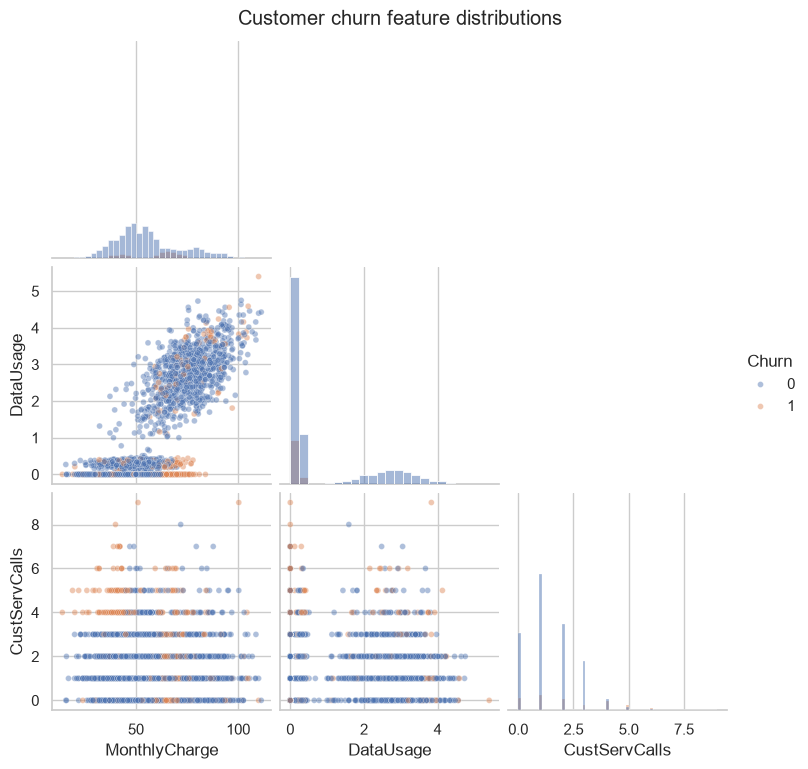

In [2]:
plot_features = ["MonthlyCharge", "DataUsage", "CustServCalls", "Churn"]
pair_grid = sns.pairplot(
    train_df[plot_features],
    hue="Churn",
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.45, "s": 18},
)
pair_grid.fig.suptitle("Customer churn feature distributions", y=1.02)
plt.show()

# Step #3 Create a Stratified Holdout Set

In [3]:
features = [
    "AccountWeeks",
    "ContractRenewal",
    "DataPlan",
    "DataUsage",
    "CustServCalls",
    "DayCalls",
    "MonthlyCharge",
    "OverageFee",
    "RoamMins",
]
X = train_df[features].copy()
y = train_df["Churn"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y,
)
print(f"Training rows: {len(X_train):,}; test rows: {len(X_test):,}")
print(y_test.value_counts(normalize=True).rename("test_share"))

Training rows: 2,333; test rows: 1,000
Churn
0    0.855
1    0.145
Name: test_share, dtype: float64


# Step #4 Tune the Random Forest on Training Data

In [4]:
pipeline = Pipeline(
    steps=[
        (
            "classifier",
            RandomForestClassifier(
                class_weight="balanced",
                random_state=RANDOM_STATE,
                n_jobs=1,
            ),
        )
    ]
)
param_grid = {
    "classifier__max_depth": [8, 16, None],
    "classifier__n_estimators": [128, 256],
    "classifier__min_samples_split": [5, 20],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid_results = GridSearchCV(
    pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=1,
    return_train_score=True,
)
grid_results.fit(X_train, y_train)

results_filtered = (
    pd.DataFrame(grid_results.cv_results_)
    .sort_values("rank_test_score")
    [[
        "param_classifier__max_depth",
        "param_classifier__min_samples_split",
        "param_classifier__n_estimators",
        "mean_test_score",
        "std_test_score",
        "rank_test_score",
    ]]
)
print(f"Best cross-validated ROC AUC: {grid_results.best_score_:.3f}")
print(f"Best parameters: {grid_results.best_params_}")
results_filtered.head(8)

Best cross-validated ROC AUC: 0.916
Best parameters: {'classifier__max_depth': 16, 'classifier__min_samples_split': 20, 'classifier__n_estimators': 256}


,param_classifier__max_depth,param_classifier__min_samples_split,param_classifier__n_estimators,mean_test_score,std_test_score,rank_test_score
7,16,20,256,0.915830,0.024187,1
11,None,20,256,0.915765,0.024113,2
8,None,5,128,0.914759,0.024280,3
10,None,20,128,0.914605,0.025981,4
6,16,20,128,0.914558,0.025916,5
9,None,5,256,0.914498,0.024468,6
5,16,5,256,0.914331,0.025662,7
4,16,5,128,0.914069,0.026447,8


# Step #5 Evaluate the Best Model Against a Baseline

Dummy ROC AUC: 0.500
Random forest ROC AUC: 0.874
              precision    recall  f1-score   support

      stayed      0.962     0.894     0.927       855
     churned      0.558     0.793     0.655       145

    accuracy                          0.879      1000
   macro avg      0.760     0.843     0.791      1000
weighted avg      0.904     0.879     0.887      1000



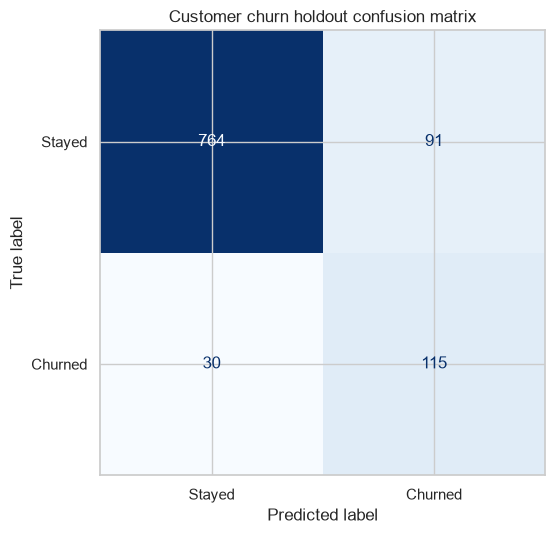

In [5]:
best_clf = grid_results.best_estimator_
y_pred = best_clf.predict(X_test)
y_probability = best_clf.predict_proba(X_test)[:, 1]

dummy = DummyClassifier(strategy="prior", random_state=RANDOM_STATE)
dummy.fit(X_train, y_train)
dummy_probability = dummy.predict_proba(X_test)[:, 1]

print(f"Dummy ROC AUC: {roc_auc_score(y_test, dummy_probability):.3f}")
print(f"Random forest ROC AUC: {roc_auc_score(y_test, y_probability):.3f}")
print(classification_report(y_test, y_pred, target_names=["stayed", "churned"], digits=3))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Stayed", "Churned"],
    cmap="Blues",
    colorbar=False,
    ax=ax,
)
ax.set_title("Customer churn holdout confusion matrix")
plt.tight_layout()
plt.show()

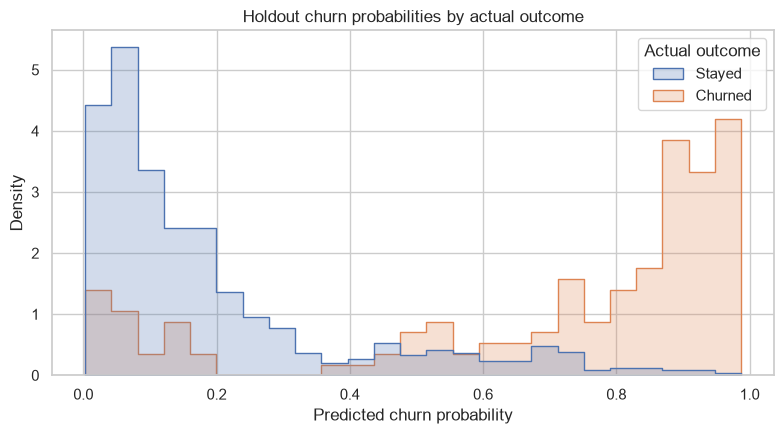

In [6]:
probability_df = pd.DataFrame(
    {
        "Predicted churn probability": y_probability,
        "Actual outcome": y_test.map({0: "Stayed", 1: "Churned"}).to_numpy(),
    }
)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(
    data=probability_df,
    x="Predicted churn probability",
    hue="Actual outcome",
    bins=25,
    element="step",
    stat="density",
    common_norm=False,
    ax=ax,
)
ax.set_title("Holdout churn probabilities by actual outcome")
plt.tight_layout()
plt.show()

# Step #6 Measure Holdout Permutation Importance

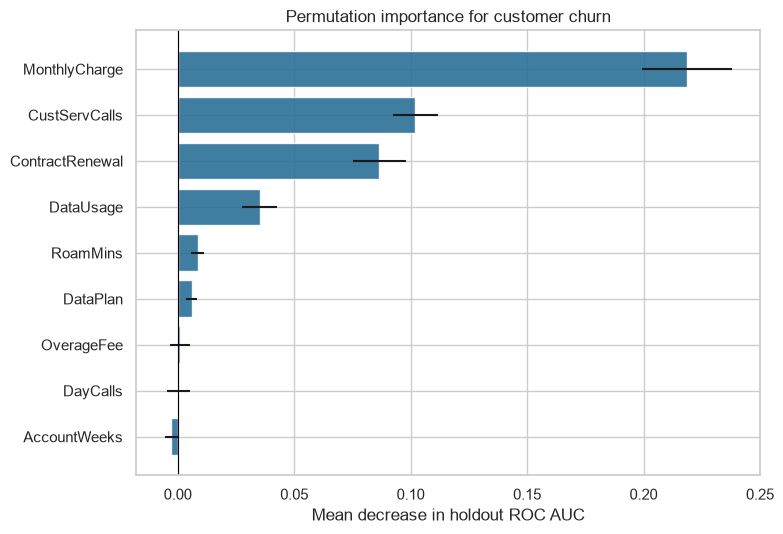

,feature,mean_auc_decrease,std
6,MonthlyCharge,0.218630,0.019300
4,CustServCalls,0.102029,0.009572
1,ContractRenewal,0.086516,0.011341
3,DataUsage,0.035099,0.007395
8,RoamMins,0.008524,0.002819
2,DataPlan,0.005938,0.002439
7,OverageFee,0.001003,0.004305
5,DayCalls,0.000396,0.004866
0,AccountWeeks,-0.002711,0.002959


In [7]:
importance = permutation_importance(
    best_clf,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=20,
    random_state=RANDOM_STATE,
    n_jobs=1,
)
importance_df = (
    pd.DataFrame(
        {
            "feature": X_test.columns,
            "mean_auc_decrease": importance.importances_mean,
            "std": importance.importances_std,
        }
    )
    .sort_values("mean_auc_decrease", ascending=True)
)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(
    importance_df["feature"],
    importance_df["mean_auc_decrease"],
    xerr=importance_df["std"],
    color="#2a6f97",
    alpha=0.9,
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Mean decrease in holdout ROC AUC")
ax.set_title("Permutation importance for customer churn")
plt.tight_layout()
plt.show()
importance_df.sort_values("mean_auc_decrease", ascending=False)